# HSTU From Scratch: Training on MovieLens-1M

Companion notebook for *I Built an HSTU From Scratch in PyTorch* (RecSys for MLEs Part 9d).

**What this notebook does:**

1. Downloads the MovieLens-1M dataset and maps ratings to action types (POSITIVE / NEUTRAL / NEGATIVE)
2. Encodes the data into per-user time-sorted sequences (same data prep as the rectools notebook)
3. Defines the fused input layer, HSTU block (3 sub-layers), and retrieval + rating prediction heads
4. Trains with epoch-based loop, recall@10 validation, early stopping, and best-model checkpointing
5. Trains two models: one WITH action types, one WITHOUT — to measure the impact of rating sentiment
6. Evaluates HR@10 and NDCG@10 against a leave-one-out test split
7. Shows example predictions: what the model actually recommends for real users
8. Demonstrates retrieval: brute-force and FAISS-based approximate nearest neighbor search
9. Demonstrates ranking: scoring candidates by retrieval score and predicted rating
10. Reproduces the SiLU vs softmax ablation
11. Implements M-FALCON inference caching and benchmarks it against naive scoring
12. Inspects the learned time-bias curve

**Hardware:** any GPU with >= 8 GB VRAM works for the default config (D=64, N=2, T=200, batch=256). Falls back to CPU but slow.

## 0. Setup

In [1]:
import os
import math
import time
import zipfile
from copy import deepcopy
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch: {torch.__version__}")
print(f"Device:  {device}")
if device == "cuda":
    print(f"GPU:     {torch.cuda.get_device_name(0)}")

! pip install faiss-cpu

PyTorch: 2.10.0+cu128
Device:  cuda
GPU:     Tesla T4
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.2/18.2 MB 79.2 MB/s eta 0:00:00:00:0100:01


## 1. The dataset: MovieLens-1M ratings -> (item, action, time) triples

We use the [MovieLens-1M dataset](https://grouplens.org/datasets/movielens/1m/) from GroupLens. Each row is a user-movie rating with a timestamp.

We map each rating to an action type based on sentiment:

- `POSITIVE` (rating >= 4): the user liked the movie
- `NEUTRAL` (rating = 3): the user was indifferent
- `NEGATIVE` (rating < 3): the user disliked the movie

The actual rating value (1-5) is kept for the rating prediction head.

In [2]:
DATA_DIR = Path("ml-1m")
ZIP_PATH = Path("ml-1m.zip")

if not DATA_DIR.exists():
    if not ZIP_PATH.exists():
        print("Downloading MovieLens-1M...")
        !wget -q https://files.grouplens.org/datasets/movielens/ml-1m.zip
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall(".")
    print("Extracted to ml-1m/")
else:
    print("ml-1m/ already exists.")

ratings = pd.read_csv(
    DATA_DIR / "ratings.dat",
    sep="::",
    header=None,
    names=["user", "item", "rating", "ts"],
    engine="python",
)

movies = pd.read_csv(
    DATA_DIR / "movies.dat",
    sep="::",
    header=None,
    names=["item", "title", "genres"],
    engine="python",
    encoding="latin-1",
)

id2title = dict(zip(movies["item"], movies["title"]))
id2genres = dict(zip(movies["item"], movies["genres"].str.split("|")))

GENRE_COLORS = {
    "Action": "#ef4444", "Adventure": "#f97316", "Animation": "#a855f7",
    "Children's": "#ec4899", "Comedy": "#eab308", "Crime": "#64748b",
    "Documentary": "#06b6d4", "Drama": "#3b82f6", "Fantasy": "#8b5cf6",
    "Film-Noir": "#1e293b", "Horror": "#dc2626", "Musical": "#d946ef",
    "Mystery": "#6366f1", "Romance": "#f43f5e", "Sci-Fi": "#22d3ee",
    "Thriller": "#f59e0b", "War": "#78716c", "Western": "#a16207",
}

print(f"Ratings: {len(ratings):,}")
print(f"Users:   {ratings.user.nunique():,}")
print(f"Movies:  {ratings.item.nunique():,}")
print(f"\nRating distribution:")
print(ratings.rating.value_counts().sort_index())
ratings.head()

Extracted to ml-1m/
Ratings: 1,000,209
Users:   6,040
Movies:  3,706

Rating distribution:
rating
1     56174
2    107557
3    261197
4    348971
5    226310
Name: count, dtype: int64


,user,item,rating,ts
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968
3,1,3408,4,978300275
4,1,2355,5,978824291


### 1.1 Map ratings to action types

In [3]:
def rating_to_action(rating):
    if rating >= 4:
        return "POSITIVE"
    elif rating == 3:
        return "NEUTRAL"
    else:
        return "NEGATIVE"

events = ratings.copy()
events["action"] = events["rating"].apply(rating_to_action)
events["value"] = events["rating"].astype(np.float32)
events = events[["user", "item", "action", "ts", "value"]]

print(f"Events: {len(events):,}")
print(f"\nAction breakdown:")
print(events.action.value_counts())
events.head(8)

Events: 1,000,209

Action breakdown:
action
POSITIVE    575281
NEUTRAL     261197
NEGATIVE    163731
Name: count, dtype: int64


,user,item,action,ts,value
0,1,1193,POSITIVE,978300760,5.0
1,1,661,NEUTRAL,978302109,3.0
2,1,914,NEUTRAL,978301968,3.0
3,1,3408,POSITIVE,978300275,4.0
4,1,2355,POSITIVE,978824291,5.0
5,1,1197,NEUTRAL,978302268,3.0
6,1,1287,POSITIVE,978302039,5.0
7,1,2804,POSITIVE,978300719,5.0


### 1.2 No filtering (matches rectools)

The rectools notebook uses all 1M interactions with no k-core filtering. We do the same here so results are directly comparable.

In [4]:
# No k-core filtering — matches rectools notebook which uses all interactions
print(f"Events: {len(events):,}, {events.user.nunique():,} users, {events.item.nunique():,} items")
print("(No k-core filtering applied — same data as rectools notebook)")

Events: 1,000,209, 6,040 users, 3,706 items
(No k-core filtering applied — same data as rectools notebook)


### 1.3 Encode IDs and build per-user sequences

Index `0` is reserved for padding in both vocabularies.

In [5]:
item2id = {v: i + 1 for i, v in enumerate(sorted(events["item"].unique()))}
action2id = {"NEGATIVE": 1, "NEUTRAL": 2, "POSITIVE": 3}
id2item = {v: k for k, v in item2id.items()}
id2action = {v: k for k, v in action2id.items()}

events["item_id"] = events["item"].map(item2id)
events["action_id"] = events["action"].map(action2id)

NUM_ITEMS = len(item2id)
NUM_ACTIONS = len(action2id)
print(f"Item vocab:   {NUM_ITEMS:,}")
print(f"Action vocab: {NUM_ACTIONS}")

events = events.sort_values(["user", "ts"]).reset_index(drop=True)

sequences = []
for user, grp in events.groupby("user", sort=False):
    if len(grp) < 3:
        continue
    sequences.append({
        "items": grp["item_id"].astype(np.int64).values,
        "actions": grp["action_id"].astype(np.int64).values,
        "times": grp["ts"].astype(np.int64).values,
        "values": grp["value"].astype(np.float32).values,
    })

print(f"\nTotal sequences: {len(sequences):,}")
print(f"Avg seq length:  {np.mean([len(s['items']) for s in sequences]):.1f}")
print(f"Max seq length:  {max(len(s['items']) for s in sequences)}")

Item vocab:   3,706
Action vocab: 3

Total sequences: 6,040
Avg seq length:  165.6
Max seq length:  2314


In [6]:
import re
from IPython.display import display, HTML

def movie_name(item_id):
    """Resolve an internal item ID to the movie title."""
    original_id = id2item.get(item_id, item_id)
    return id2title.get(original_id, str(original_id))

def movie_genres(item_id):
    """Resolve an internal item ID to genre list."""
    original_id = id2item.get(item_id, item_id)
    return id2genres.get(original_id, [])

def parse_year(title):
    m = re.search(r'\((\d{4})\)', title)
    return m.group(1) if m else ""

def clean_title(title):
    return re.sub(r'\s*\(\d{4}\)\s*$', '', title)

print(f"Item 1 = {movie_name(1)}")
print(f"Item 100 = {movie_name(100)}")

Item 1 = Toy Story (1995)
Item 100 = Mr. Wrong (1996)


### 1.4 Train/test split (leave-one-out)

For each user: last event → test, rest → train history. During training, the last item of the training history is held out for validation (leave-one-out, same as rectools).

In [7]:
MAX_SEQ_LEN = 200

def split_seq(seq, max_len=MAX_SEQ_LEN):
    n = len(seq["items"])
    if n < 3:
        return None
    history_slice = slice(max(0, n - 1 - max_len), n - 1)
    history = {
        "items": seq["items"][history_slice].tolist(),
        "actions": seq["actions"][history_slice].tolist(),
        "times": seq["times"][history_slice].tolist(),
        "values": seq["values"][history_slice].tolist(),
    }
    test_target = (
        int(seq["items"][n - 1]),
        int(seq["actions"][n - 1]),
        int(seq["times"][n - 1]),
        float(seq["values"][n - 1]),
    )
    return history, test_target

splits = [s for s in (split_seq(seq) for seq in sequences) if s is not None]

print(f"Train/test sequences: {len(splits):,}")

Train/test sequences: 6,040


### 1.5 Dataset class

**Training**: shift-by-one prediction (same as SASRec/rectools). For each user, the model takes `items[:-1]` as input and predicts `items[1:]` — every position in the sequence is a supervision target. With avg sequence length ~165 on ML-1M, this gives ~165× more signal per epoch than single-target sampling.

**Validation**: leave-one-out from the training history (matches rectools `leave_one_out_mask`). Last item of the training sequence is the target, everything before is context.

**Test**: full training history as context, predict the held-out test item.

The `use_actions` flag controls whether the model sees action types (POSITIVE/NEUTRAL/NEGATIVE) or a constant action ID. This lets us ablate the contribution of rating sentiment.

In [8]:
class HSTUDataset(Dataset):
    """Train: shift-by-one full-sequence prediction (SASRec-style).
    Val: leave-one-out from training history.
    Test: full training history as context, predict held-out test item."""
    def __init__(self, splits, num_items, num_negatives=128, mode="train", use_actions=True):
        self.splits = splits
        self.num_items = num_items
        self.num_negatives = num_negatives
        self.mode = mode
        self.use_actions = use_actions

    def __len__(self):
        return len(self.splits)

    def __getitem__(self, idx):
        history, test_target = self.splits[idx]
        items = np.asarray(history["items"])
        actions = np.asarray(history["actions"])
        times = np.asarray(history["times"])
        values = np.asarray(history["values"])

        n = len(items)

        if self.mode == "train":
            if n > MAX_SEQ_LEN + 1:
                items = items[-(MAX_SEQ_LEN + 1):]
                actions = actions[-(MAX_SEQ_LEN + 1):]
                times = times[-(MAX_SEQ_LEN + 1):]
                values = values[-(MAX_SEQ_LEN + 1):]

            hist_items = items[:-1]
            hist_actions = actions[:-1]
            hist_times = times[:-1]
            target_items = items[1:]
            target_values = values[1:]

            if not self.use_actions:
                hist_actions = np.ones_like(hist_actions)

            # Per-position random negatives — matches rectools CatalogUniformSampler:
            # every (sequence, position) pair gets its own K independent draws.
            seq_len = len(hist_items)
            neg_items = np.random.randint(1, self.num_items + 1,
                                          size=(seq_len, self.num_negatives))

            return {
                "hist_items": hist_items.astype(np.int64),
                "hist_actions": hist_actions.astype(np.int64),
                "hist_times": hist_times.astype(np.int64),
                "target_items": target_items.astype(np.int64),
                "target_values": target_values.astype(np.float32),
                "neg_items": neg_items.astype(np.int64),
            }

        elif self.mode == "val":
            target_item = int(items[-1])
            target_value = float(values[-1])
            hist_items = items[:-1][-MAX_SEQ_LEN:]
            hist_actions = actions[:-1][-MAX_SEQ_LEN:]
            hist_times = times[:-1][-MAX_SEQ_LEN:]
        else:  # test
            target_item = test_target[0]
            target_value = test_target[3]
            hist_items = items[-MAX_SEQ_LEN:]
            hist_actions = actions[-MAX_SEQ_LEN:]
            hist_times = times[-MAX_SEQ_LEN:]

        if not self.use_actions:
            hist_actions = np.ones_like(hist_actions)

        return {
            "hist_items": hist_items.astype(np.int64),
            "hist_actions": hist_actions.astype(np.int64),
            "hist_times": hist_times.astype(np.int64),
            "target_item": target_item,
            "rating_label": float(target_value),
        }

def collate_fn(batch):
    """Pad histories, shifted targets, and per-position negatives."""
    max_len = max(len(b["hist_items"]) for b in batch)
    if max_len == 0:
        max_len = 1
    B = len(batch)
    K = batch[0]["neg_items"].shape[1]

    hist_items = np.zeros((B, max_len), dtype=np.int64)
    hist_actions = np.zeros((B, max_len), dtype=np.int64)
    hist_times = np.zeros((B, max_len), dtype=np.int64)
    target_items = np.zeros((B, max_len), dtype=np.int64)
    target_values = np.zeros((B, max_len), dtype=np.float32)
    attn_mask = np.zeros((B, max_len), dtype=np.bool_)
    neg_items = np.zeros((B, max_len, K), dtype=np.int64)

    for i, b in enumerate(batch):
        L = len(b["hist_items"])
        hist_items[i, :L] = b["hist_items"]
        hist_actions[i, :L] = b["hist_actions"]
        hist_times[i, :L] = b["hist_times"]
        target_items[i, :L] = b["target_items"]
        target_values[i, :L] = b["target_values"]
        attn_mask[i, :L] = True
        neg_items[i, :L] = b["neg_items"]

    return {
        "hist_items": torch.from_numpy(hist_items),
        "hist_actions": torch.from_numpy(hist_actions),
        "hist_times": torch.from_numpy(hist_times),
        "attn_mask": torch.from_numpy(attn_mask),
        "target_items": torch.from_numpy(target_items),
        "target_values": torch.from_numpy(target_values),
        "neg_items": torch.from_numpy(neg_items),
    }

print("HSTUDataset defined with per-position negatives (matches rectools).")

HSTUDataset defined with per-position negatives (matches rectools).


## 2. The fused input layer

Item embedding + action embedding \u2192 concatenate \u2192 MLP \u2192 fused vector.

In [9]:
class FusedInputEmbedding(nn.Module):
    def __init__(self, num_items, num_actions, dim):
        super().__init__()
        self.item_emb = nn.Embedding(num_items + 1, dim, padding_idx=0)
        self.action_emb = nn.Embedding(num_actions + 1, dim, padding_idx=0)
        # Larger-than-BERT init: with dim=64 and full-vocab softmax, embeddings
        # need norm ~1 for meaningful initial gradient flow. std=0.02 is too
        # small (norm 0.16); default N(0,1) is too large (norm 8).
        nn.init.normal_(self.item_emb.weight, std=0.1)
        nn.init.normal_(self.action_emb.weight, std=0.1)
        with torch.no_grad():
            self.item_emb.weight[0].zero_()
            self.action_emb.weight[0].zero_()
        self.fuse = nn.Sequential(
            nn.Linear(2 * dim, dim),
            nn.SiLU(),
            nn.Linear(dim, dim),
        )

    def forward(self, item_ids, action_ids):
        i = self.item_emb(item_ids)
        a = self.action_emb(action_ids)
        return self.fuse(torch.cat([i, a], dim=-1))

## 3. The HSTU block

Three sub-layers: pointwise projection \u2192 spatial aggregation (with RAB) \u2192 gated transformation.

In [10]:
class RelativeAttentionBias(nn.Module):
    """Learnable position + time biases, added to QK^T before SiLU."""
    TIME_BUCKETS = [
        (0, 3600),                   # 0-1 hour
        (3600, 86400),               # 1-24 hours
        (86400, 86400 * 7),          # 1-7 days
        (86400 * 7, 86400 * 30),     # 7-30 days
        (86400 * 30, float("inf")),  # 30+ days
    ]

    def __init__(self, max_seq_len):
        super().__init__()
        self.max_seq_len = max_seq_len
        self.pos_bias = nn.Embedding(2 * max_seq_len - 1, 1)
        self.time_bias = nn.Embedding(len(self.TIME_BUCKETS), 1)
        nn.init.zeros_(self.pos_bias.weight)
        nn.init.zeros_(self.time_bias.weight)

    def _bucket(self, time_deltas):
        out = torch.zeros_like(time_deltas, dtype=torch.long)
        for k, (lo, hi) in enumerate(self.TIME_BUCKETS):
            mask = (time_deltas >= lo) & (time_deltas < hi)
            out = torch.where(mask, torch.full_like(out, k), out)
        return out

    def forward(self, times):
        B, T = times.shape
        idx = torch.arange(T, device=times.device)
        rel_pos = (idx.view(T, 1) - idx.view(1, T)) + (self.max_seq_len - 1)
        pos_b = self.pos_bias(rel_pos).squeeze(-1)
        time_deltas = (times.unsqueeze(2) - times.unsqueeze(1)).abs()
        bucket_idx = self._bucket(time_deltas)
        time_b = self.time_bias(bucket_idx).squeeze(-1)
        return pos_b.unsqueeze(0) + time_b

In [11]:
class HSTUBlock(nn.Module):
    def __init__(self, dim, max_seq_len, use_softmax=False, dropout=0.2):
        super().__init__()
        self.linear_in = nn.Linear(dim, 4 * dim)
        self.rab = RelativeAttentionBias(max_seq_len)
        self.norm = nn.LayerNorm(dim)
        self.linear_out = nn.Linear(dim, dim)
        self.dropout = nn.Dropout(dropout)
        self.use_softmax = use_softmax

    def forward(self, x, times, attn_mask):
        B, T, D = x.shape
        proj = F.silu(self.linear_in(x))
        K, Q, V, U = proj.chunk(4, dim=-1)

        scores = torch.matmul(Q, K.transpose(-2, -1))
        scores = scores + self.rab(times)
        causal = torch.tril(torch.ones(T, T, device=x.device))
        scores = scores * causal

        pad_mask = attn_mask.unsqueeze(1).float()
        scores = scores * pad_mask

        if self.use_softmax:
            mask_neg_inf = (1.0 - pad_mask * causal.unsqueeze(0)) * -1e9
            activated = F.softmax(scores + mask_neg_inf, dim=-1)
            attn_out = torch.matmul(activated, V)
        else:
            activated = F.silu(scores)
            attn_out = torch.matmul(activated, V) / max(T, 1)

        gated = self.norm(attn_out) * U
        output = self.dropout(self.linear_out(gated))
        return output + x

In [12]:
class HSTUEncoder(nn.Module):
    def __init__(self, num_items, num_actions, dim, num_layers, max_seq_len,
                 use_softmax=False, dropout=0.2):
        super().__init__()
        self.embed = FusedInputEmbedding(num_items, num_actions, dim)
        self.blocks = nn.ModuleList([
            HSTUBlock(dim, max_seq_len, use_softmax=use_softmax, dropout=dropout)
            for _ in range(num_layers)
        ])

    def forward(self, item_ids, action_ids, times, attn_mask):
        x = self.embed(item_ids, action_ids)
        for block in self.blocks:
            x = block(x, times, attn_mask)
        return x

## 4. Retrieval + rating prediction

- **Retrieval head**: dot product against item embedding matrix (tied weights), full-vocabulary cross-entropy loss applied at every position via shift-by-one supervision.
- **Rating head**: predicts the user's rating (1-5) for a candidate item (MSE loss), trained at every position alongside retrieval.

In [13]:
class HSTUModel(nn.Module):
    def __init__(self, num_items, num_actions, dim, num_layers, max_seq_len,
                 use_softmax=False, dropout=0.2):
        super().__init__()
        self.encoder = HSTUEncoder(num_items, num_actions, dim, num_layers, max_seq_len,
                                   use_softmax=use_softmax, dropout=dropout)
        self.rating_head = nn.Sequential(nn.Linear(dim, dim), nn.SiLU(), nn.Linear(dim, 1))

    def forward(self, item_ids, action_ids, times, attn_mask):
        h = self.encoder(item_ids, action_ids, times, attn_mask)
        last_idx = attn_mask.sum(dim=1).clamp(min=1) - 1
        user_state = h[torch.arange(h.size(0), device=h.device), last_idx]
        return h, user_state

    def retrieval_logits(self, user_state):
        # Cosine similarity (matches rectools HSTU SimilarityModule)
        item_emb = self.encoder.embed.item_emb.weight
        us_n = F.normalize(user_state, dim=-1, eps=1e-8)
        emb_n = F.normalize(item_emb, dim=-1, eps=1e-8)
        return us_n @ emb_n.T

    def rating_pred(self, user_state, candidate_item_id):
        cand = self.encoder.embed.item_emb(candidate_item_id)
        return self.rating_head(user_state + cand).squeeze(-1)

In [14]:
W_RETRIEVAL = 1.0
W_RATING = 0.2
LOGITS_T = 0.05  # Temperature — matches rectools `logits_t=0.05` (cosine sim ×20)

def compute_loss(model, batch, device):
    hist_items = batch["hist_items"].to(device)
    hist_actions = batch["hist_actions"].to(device)
    hist_times = batch["hist_times"].to(device)
    attn_mask = batch["attn_mask"].to(device)
    target_items = batch["target_items"].to(device)    # (B, T)
    target_values = batch["target_values"].to(device)  # (B, T)
    neg_items = batch["neg_items"].to(device)          # (B, T, K)

    # Encoder hidden states at every position
    h, _ = model(hist_items, hist_actions, hist_times, attn_mask)  # (B, T, D)
    B, T, D = h.shape

    pos_emb = model.encoder.embed.item_emb(target_items)  # (B, T, D)
    neg_emb = model.encoder.embed.item_emb(neg_items)     # (B, T, K, D)

    # --- Retrieval (sampled softmax with cosine similarity + temperature) ---
    # Matches rectools: cosine sim, divide by logits_t=0.05, sampled softmax with K=128.
    h_n = F.normalize(h, dim=-1, eps=1e-8)
    pos_n = F.normalize(pos_emb, dim=-1, eps=1e-8)
    neg_n = F.normalize(neg_emb, dim=-1, eps=1e-8)

    pos_logit = (h_n * pos_n).sum(-1, keepdim=True) / LOGITS_T              # (B, T, 1)
    neg_logit = torch.einsum("btd,btkd->btk", h_n, neg_n) / LOGITS_T        # (B, T, K)
    all_logits = torch.cat([pos_logit, neg_logit], dim=-1)                  # (B, T, K+1)

    target_idx = torch.zeros(B, T, dtype=torch.long, device=device)
    losses = F.cross_entropy(
        all_logits.reshape(B * T, -1),
        target_idx.reshape(B * T),
        reduction="none",
    )

    valid = attn_mask.reshape(B * T).float()
    n_valid = valid.sum().clamp(min=1)
    l_retrieval = (losses * valid).sum() / n_valid

    # --- Rating prediction at every valid position (auxiliary, our addition) ---
    pred_rating = model.rating_head(h + pos_emb).squeeze(-1)
    rating_se = (pred_rating - target_values) ** 2
    l_rating = (rating_se.reshape(B * T) * valid).sum() / n_valid

    total = W_RETRIEVAL * l_retrieval + W_RATING * l_rating
    return total, {
        "loss": total.item(),
        "retrieval": l_retrieval.item(),
        "rating": l_rating.item(),
    }

## 5. Training loop

Epoch-based training with cosine LR schedule, recall@10 validation after each epoch, early stopping, and best-model checkpointing — matching the rectools notebook setup.

In [15]:
DIM = 64
NUM_LAYERS = 2
BATCH_SIZE = 128             # matches rectools
LR = 1e-3                    # matches rectools (constant, no schedule)
GRAD_CLIP = 1.0
NUM_NEGATIVES = 128          # matches rectools
DROPOUT = 0.2                # matches rectools
MAX_EPOCHS = 100             # matches rectools
PATIENCE = 10                # matches rectools
ADAM_BETAS = (0.9, 0.98)     # matches rectools (hardcoded in their base.py)

# --- Datasets WITH actions (POSITIVE / NEUTRAL / NEGATIVE) ---
train_ds_act = HSTUDataset(splits, NUM_ITEMS, num_negatives=NUM_NEGATIVES, mode="train", use_actions=True)
val_ds_act = HSTUDataset(splits, NUM_ITEMS, num_negatives=NUM_NEGATIVES, mode="val", use_actions=True)
test_ds_act = HSTUDataset(splits, NUM_ITEMS, num_negatives=NUM_NEGATIVES, mode="test", use_actions=True)

# --- Datasets WITHOUT actions (constant action_id=1, matches rectools) ---
train_ds_noact = HSTUDataset(splits, NUM_ITEMS, num_negatives=NUM_NEGATIVES, mode="train", use_actions=False)
val_ds_noact = HSTUDataset(splits, NUM_ITEMS, num_negatives=NUM_NEGATIVES, mode="val", use_actions=False)
test_ds_noact = HSTUDataset(splits, NUM_ITEMS, num_negatives=NUM_NEGATIVES, mode="test", use_actions=False)

def make_model(use_softmax=False):
    model = HSTUModel(NUM_ITEMS, NUM_ACTIONS, DIM, NUM_LAYERS, MAX_SEQ_LEN,
                     use_softmax=use_softmax, dropout=DROPOUT).to(device)
    # Xavier normal init for all 2D+ params (matches rectools `_xavier_normal_init`)
    for param in model.parameters():
        if param.dim() > 1:
            nn.init.xavier_normal_(param.data)
    # Re-zero the padding row in embeddings
    with torch.no_grad():
        model.encoder.embed.item_emb.weight[0].zero_()
        model.encoder.embed.action_emb.weight[0].zero_()
    return model

# ---------------------------------------------------------------------------
# Recall@10 on validation set (matches rectools RecallCallback)
# ---------------------------------------------------------------------------
@torch.no_grad()
def compute_recall(model, val_dataset, k=10):
    """Full-vocab cosine ranking with seen-item masking over all val users."""
    model.eval()
    hits = 0
    n_eval = 0
    for idx in range(len(val_dataset)):
        sample = val_dataset[idx]
        hist_items_np = sample["hist_items"]
        hist_items = torch.from_numpy(hist_items_np).unsqueeze(0).to(device)
        hist_actions = torch.from_numpy(sample["hist_actions"]).unsqueeze(0).to(device)
        hist_times = torch.from_numpy(sample["hist_times"]).unsqueeze(0).to(device)
        attn_mask = torch.ones_like(hist_items, dtype=torch.bool)
        if hist_items.size(1) == 0:
            continue
        target = sample["target_item"]

        _, user_state = model(hist_items, hist_actions, hist_times, attn_mask)
        logits = model.retrieval_logits(user_state).squeeze(0)

        # Mask padding and seen items
        logits[0] = -float("inf")
        seen = hist_items_np[hist_items_np > 0]
        logits[seen] = -float("inf")

        _, topk_ids = logits.topk(k)
        if target in topk_ids.cpu().numpy():
            hits += 1
        n_eval += 1

    return hits / max(n_eval, 1)

# ---------------------------------------------------------------------------
# Training loop — matches rectools: plain Adam, no schedule, early stop on recall
# ---------------------------------------------------------------------------
def train(model, train_ds, val_ds, max_epochs=MAX_EPOCHS, patience=PATIENCE):
    loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                        collate_fn=collate_fn, num_workers=0, drop_last=True)

    # Plain Adam with rectools betas, no weight decay, no LR schedule
    optimizer = torch.optim.Adam(model.parameters(), lr=LR, betas=ADAM_BETAS)

    best_recall = 0.0
    best_state = None
    no_improve = 0
    history = {"epoch": [], "train_loss": [], "retrieval": [], "rating": [], "recall@10": []}
    t0 = time.time()

    for epoch in range(max_epochs):
        model.train()
        epoch_loss = 0.0
        epoch_ret = 0.0
        epoch_rat = 0.0
        n_batches = 0
        for batch in loader:
            total_loss, parts = compute_loss(model, batch, device)
            optimizer.zero_grad()
            total_loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            optimizer.step()
            epoch_loss += parts["loss"]
            epoch_ret += parts["retrieval"]
            epoch_rat += parts["rating"]
            n_batches += 1

        avg_loss = epoch_loss / max(n_batches, 1)
        avg_ret = epoch_ret / max(n_batches, 1)
        avg_rat = epoch_rat / max(n_batches, 1)

        recall = compute_recall(model, val_ds, k=10)

        history["epoch"].append(epoch)
        history["train_loss"].append(avg_loss)
        history["retrieval"].append(avg_ret)
        history["rating"].append(avg_rat)
        history["recall@10"].append(recall)

        elapsed = time.time() - t0
        marker = ""
        if recall > best_recall:
            best_recall = recall
            best_state = deepcopy(model.state_dict())
            no_improve = 0
            marker = " *"
        else:
            no_improve += 1

        print(f"epoch {epoch:3d}  loss={avg_loss:.4f}  ret={avg_ret:.4f}  rat={avg_rat:.4f}  "
              f"recall@10={recall:.4f}  best={best_recall:.4f}  ({elapsed:.0f}s){marker}")

        if no_improve >= patience:
            print(f"Early stopping at epoch {epoch} (no improvement for {patience} epochs)")
            break

    if best_state is not None:
        model.load_state_dict(best_state)
        print(f"Loaded best model (recall@10={best_recall:.4f})")

    return history

# --- Train model WITH actions ---
print("=" * 60)
print("Training HSTU with actions (POSITIVE / NEUTRAL / NEGATIVE)")
print("=" * 60)
model_with_actions = make_model(use_softmax=False)
history_act = train(model_with_actions, train_ds_act, val_ds_act)

# --- Train model WITHOUT actions ---
print("\n" + "=" * 60)
print("Training HSTU without actions (constant action_id=1, matches rectools)")
print("=" * 60)
model_no_actions = make_model(use_softmax=False)
history_noact = train(model_no_actions, train_ds_noact, val_ds_noact)

# Default aliases for downstream cells
model = model_with_actions
test_ds = test_ds_act

Training HSTU with actions (POSITIVE / NEUTRAL / NEGATIVE)
epoch   0  loss=5.2869  ret=4.5882  rat=3.4939  recall@10=0.0353  best=0.0353  (30s) *
epoch   1  loss=4.2189  ret=4.0071  rat=1.0587  recall@10=0.0536  best=0.0536  (58s) *
epoch   2  loss=4.0123  ret=3.8078  rat=1.0224  recall@10=0.0680  best=0.0680  (86s) *
epoch   3  loss=3.8632  ret=3.6626  rat=1.0029  recall@10=0.1101  best=0.1101  (115s) *
epoch   4  loss=3.6968  ret=3.5013  rat=0.9774  recall@10=0.1270  best=0.1270  (144s) *
epoch   5  loss=3.5598  ret=3.3681  rat=0.9583  recall@10=0.1369  best=0.1369  (172s) *
epoch   6  loss=3.4477  ret=3.2572  rat=0.9525  recall@10=0.1634  best=0.1634  (201s) *
epoch   7  loss=3.3399  ret=3.1511  rat=0.9440  recall@10=0.1765  best=0.1765  (230s) *
epoch   8  loss=3.2398  ret=3.0535  rat=0.9314  recall@10=0.1823  best=0.1823  (259s) *
epoch   9  loss=3.1596  ret=2.9757  rat=0.9190  recall@10=0.1969  best=0.1969  (288s) *
epoch  10  loss=3.0977  ret=2.9154  rat=0.9115  recall@10=0.2005

### 5.1 Training curves

Training loss and validation recall@10 per epoch for both models.

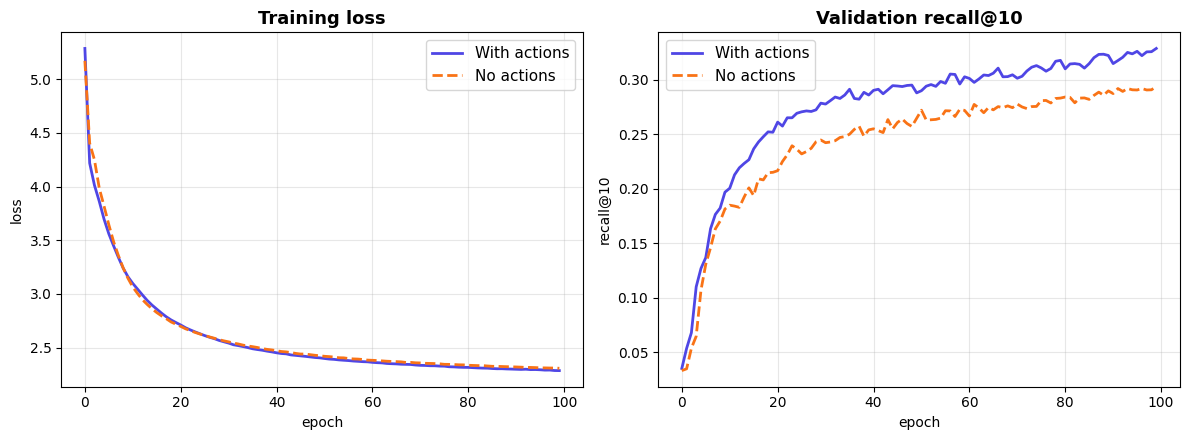

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(history_act["epoch"], history_act["train_loss"],
             color="#4f46e5", linewidth=2, label="With actions")
axes[0].plot(history_noact["epoch"], history_noact["train_loss"],
             color="#f97316", linewidth=2, label="No actions", linestyle="--")
axes[0].set_title("Training loss", fontsize=13, fontweight="bold")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("loss")
axes[0].legend(fontsize=11)
axes[0].grid(True, alpha=0.3)

axes[1].plot(history_act["epoch"], history_act["recall@10"],
             color="#4f46e5", linewidth=2, label="With actions")
axes[1].plot(history_noact["epoch"], history_noact["recall@10"],
             color="#f97316", linewidth=2, label="No actions", linestyle="--")
axes[1].set_title("Validation recall@10", fontsize=13, fontweight="bold")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("recall@10")
axes[1].legend(fontsize=11)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 6. Evaluation: HR@10 and NDCG@10

Full-vocabulary ranking: for each test user, score the held-out item against **all** items, then check whether it lands in the top 10.

In [17]:
@torch.no_grad()
def evaluate(model, dataset, k=10):
    """Full-vocabulary ranking with seen-item masking over all test users."""
    model.eval()
    hits = 0
    ndcg = 0.0
    n_eval = 0
    for idx in range(len(dataset)):
        sample = dataset[idx]
        hist_items_np = sample["hist_items"]
        hist_items = torch.from_numpy(hist_items_np).unsqueeze(0).to(device)
        hist_actions = torch.from_numpy(sample["hist_actions"]).unsqueeze(0).to(device)
        hist_times = torch.from_numpy(sample["hist_times"]).unsqueeze(0).to(device)
        attn_mask = torch.ones_like(hist_items, dtype=torch.bool)
        if hist_items.size(1) == 0:
            continue
        target = sample["target_item"]

        _, user_state = model(hist_items, hist_actions, hist_times, attn_mask)
        logits = model.retrieval_logits(user_state).squeeze(0)

        # Mask padding and seen items
        logits[0] = -float("inf")
        seen = hist_items_np[hist_items_np > 0]
        logits[seen] = -float("inf")

        _, topk_ids = logits.topk(k)
        topk_list = topk_ids.cpu().numpy()
        if target in topk_list:
            rank = np.where(topk_list == target)[0][0]
            hits += 1
            ndcg += 1.0 / math.log2(rank + 2)
        n_eval += 1

    return hits / max(n_eval, 1), ndcg / max(n_eval, 1)

# Evaluate both models on test set
hr_act, ndcg_act = evaluate(model_with_actions, test_ds_act)
print(f"HSTU (with actions)    -> HR@10: {hr_act:.4f}   NDCG@10: {ndcg_act:.4f}")

hr_noact, ndcg_noact = evaluate(model_no_actions, test_ds_noact)
print(f"HSTU (no actions)      -> HR@10: {hr_noact:.4f}   NDCG@10: {ndcg_noact:.4f}")

# Aliases for ablation cell
hr, ndcg = hr_act, ndcg_act

# --- Comparison table ---
diff_hr = (hr_act - hr_noact) / max(hr_noact, 1e-9) * 100
diff_ndcg = (ndcg_act - ndcg_noact) / max(ndcg_noact, 1e-9) * 100
sign_hr = "+" if diff_hr >= 0 else ""
sign_ndcg = "+" if diff_ndcg >= 0 else ""
diff_color = "#22c55e" if diff_hr > 0 else ("#dc2626" if diff_hr < -1 else "#94a3b8")

table_html = f"""
<div style="margin: 12px 0;">
<table style="border-collapse:collapse; font-size:14px; width:auto;">
  <tr style="background:#1e293b; color:white;">
    <th style="padding:10px 20px; text-align:left;">Model</th>
    <th style="padding:10px 20px; text-align:center;">HR@10</th>
    <th style="padding:10px 20px; text-align:center;">NDCG@10</th>
    <th style="padding:10px 20px; text-align:center;">Actions</th>
  </tr>
  <tr style="background:#f0f9ff;">
    <td style="padding:10px 20px; font-weight:600; color:#4f46e5;">HSTU (with actions)</td>
    <td style="padding:10px 20px; text-align:center; font-family:monospace;">{hr_act:.4f}</td>
    <td style="padding:10px 20px; text-align:center; font-family:monospace;">{ndcg_act:.4f}</td>
    <td style="padding:10px 20px; text-align:center;">POSITIVE / NEUTRAL / NEGATIVE</td>
  </tr>
  <tr style="background:#fff7ed;">
    <td style="padding:10px 20px; font-weight:600; color:#f97316;">HSTU (no actions)</td>
    <td style="padding:10px 20px; text-align:center; font-family:monospace;">{hr_noact:.4f}</td>
    <td style="padding:10px 20px; text-align:center; font-family:monospace;">{ndcg_noact:.4f}</td>
    <td style="padding:10px 20px; text-align:center;">constant (action_id=1)</td>
  </tr>
  <tr style="background:#f1f5f9;">
    <td style="padding:10px 20px; color:#64748b;">With vs Without actions</td>
    <td style="padding:10px 20px; text-align:center; font-family:monospace; color:{diff_color};">{sign_hr}{diff_hr:.1f}%</td>
    <td style="padding:10px 20px; text-align:center; font-family:monospace; color:{diff_color};">{sign_ndcg}{diff_ndcg:.1f}%</td>
    <td style="padding:10px 20px;"></td>
  </tr>
  <tr style="background:#fafafa;">
    <td style="padding:10px 20px; font-weight:600; color:#94a3b8;">RecTools HSTU</td>
    <td style="padding:10px 20px; text-align:center; font-family:monospace; color:#94a3b8;">&mdash;</td>
    <td style="padding:10px 20px; text-align:center; font-family:monospace; color:#94a3b8;">&mdash;</td>
    <td style="padding:10px 20px; text-align:center; color:#94a3b8;">none (fill in after running rectools notebook)</td>
  </tr>
</table>
<p style="color:#94a3b8; font-size:12px; margin-top:6px;">
  The "no actions" model uses the same data prep as rectools (no k-core filtering, same split).
  Its HR@10 should be directly comparable to rectools HSTU.
</p>
</div>
"""
display(HTML(table_html))

HSTU (with actions)    -> HR@10: 0.2697   NDCG@10: 0.1524
HSTU (no actions)      -> HR@10: 0.2184   NDCG@10: 0.1181


Model,HR@10,NDCG@10,Actions
HSTU (with actions),0.2697,0.1524,POSITIVE / NEUTRAL / NEGATIVE
HSTU (no actions),0.2184,0.1181,constant (action_id=1)
With vs Without actions,+23.5%,+29.1%,
RecTools HSTU,—,—,none (fill in after running rectools notebook)


### 6.1 What does the model actually predict?

Metrics tell you the model works. Examples tell you *how* it works. We show predictions from the **with-actions** model — the action badges on history cards show the rating sentiment signal the model receives.

In [18]:
ACTION_COLORS = {"POSITIVE": "#22c55e", "NEUTRAL": "#f59e0b", "NEGATIVE": "#ef4444"}

def _movie_card(item_id, action=None, rank=None, score=None, highlight=False):
    title = movie_name(item_id)
    genres = movie_genres(item_id)[:3]
    year = parse_year(title)
    name = clean_title(title)

    border = "border:2px solid #22c55e;" if highlight else "border:1px solid #334155;"
    bg = "background:linear-gradient(135deg, rgba(34,197,94,0.12), rgba(34,197,94,0.04));" if highlight else "background:#1e293b;"

    rank_html = f'<div style="font-size:10px;color:#64748b;font-weight:700;">#{rank}</div>' if rank else ""
    score_html = f'<div style="font-size:9px;color:#64748b;font-family:monospace;margin-top:2px;">{score:.2f}</div>' if score is not None else ""
    year_html = f'<span style="font-size:9px;color:#94a3b8;background:#0f172a;padding:1px 5px;border-radius:4px;">{year}</span>' if year else ""

    action_html = ""
    if action:
        ac = ACTION_COLORS.get(action, "#64748b")
        action_html = f'<span style="font-size:8px;color:white;background:{ac};padding:1px 5px;border-radius:4px;margin-left:4px;">{action}</span>'

    genre_tags = ""
    for g in genres:
        gc = GENRE_COLORS.get(g, "#475569")
        genre_tags += f'<span style="font-size:8px;color:white;background:{gc};padding:1px 5px;border-radius:4px;margin-right:2px;">{g}</span>'

    return f'''<div style="flex:0 0 auto;width:170px;padding:10px;border-radius:10px;{border}{bg}">
        {rank_html}
        <div style="font-size:12px;color:#f1f5f9;font-weight:600;margin:4px 0 2px;
                    overflow:hidden;text-overflow:ellipsis;white-space:nowrap;" title="{title}">{name[:24]}</div>
        <div style="margin-bottom:4px;">{year_html}{action_html}</div>
        <div style="display:flex;flex-wrap:wrap;gap:2px;">{genre_tags}</div>
        {score_html}
    </div>'''

@torch.no_grad()
def show_predictions(model, dataset, indices, id2item, id2action, k=10):
    model.eval()
    for idx in indices:
        sample = dataset[idx]
        hist_items = torch.from_numpy(sample["hist_items"]).unsqueeze(0).to(device)
        hist_actions = torch.from_numpy(sample["hist_actions"]).unsqueeze(0).to(device)
        hist_times = torch.from_numpy(sample["hist_times"]).unsqueeze(0).to(device)
        attn_mask = torch.ones_like(hist_items, dtype=torch.bool)
        if hist_items.size(1) == 0:
            continue
        target = sample["target_item"]
        seq_len = hist_items.size(1)

        _, user_state = model(hist_items, hist_actions, hist_times, attn_mask)
        logits = model.retrieval_logits(user_state).squeeze(0)
        logits[0] = -float("inf")
        top_scores, top_ids = logits.topk(k)

        target_score = logits[target].item()
        target_rank = (logits > target_score).sum().item() + 1

        target_tensor = torch.tensor([target], device=device)
        pred_rating = np.clip(model.rating_pred(user_state, target_tensor).item(), 1, 5)

        items_np = sample["hist_items"]
        actions_np = sample["hist_actions"]

        start = max(0, seq_len - 8)
        hist_html = ""
        for j in range(start, seq_len):
            iid = int(items_np[j])
            aname = id2action.get(int(actions_np[j]), "?")
            hist_html += _movie_card(iid, action=aname)

        reco_html = ""
        for rank_i, (sid, score) in enumerate(zip(top_ids.cpu(), top_scores.cpu())):
            reco_html += _movie_card(sid.item(), rank=rank_i+1, score=score.item(),
                                     highlight=(sid.item() == target))

        held_name = movie_name(target)
        held_genres = movie_genres(target)[:3]
        rank_color = "#22c55e" if target_rank <= 10 else ("#f59e0b" if target_rank <= 50 else "#ef4444")

        genre_tags_held = ""
        for g in held_genres:
            gc = GENRE_COLORS.get(g, "#475569")
            genre_tags_held += f'<span style="font-size:9px;color:white;background:{gc};padding:1px 5px;border-radius:4px;margin-right:3px;">{g}</span>'

        html = f'''
        <div style="background:#0f172a;border-radius:14px;padding:20px;margin:16px 0;font-family:system-ui,-apple-system,sans-serif;">
          <div style="display:flex;justify-content:space-between;align-items:center;margin-bottom:14px;">
            <div style="color:#f8fafc;font-size:18px;font-weight:700;">User {idx}</div>
            <div style="color:#64748b;font-size:12px;">{seq_len} events in history</div>
          </div>
          <div style="color:#94a3b8;font-size:11px;margin-bottom:6px;text-transform:uppercase;letter-spacing:1.5px;font-weight:600;">Recent History</div>
          <div style="display:flex;gap:8px;overflow-x:auto;padding:4px 0 14px 0;">{hist_html}</div>
          <div style="color:#94a3b8;font-size:11px;margin-bottom:6px;text-transform:uppercase;letter-spacing:1.5px;font-weight:600;">Top-10 Predictions</div>
          <div style="display:flex;gap:8px;overflow-x:auto;padding:4px 0 14px 0;">{reco_html}</div>
          <div style="background:#1e293b;border-radius:10px;padding:14px;display:flex;align-items:center;gap:14px;">
            <div style="width:6px;height:60px;border-radius:3px;background:{rank_color};flex-shrink:0;"></div>
            <div>
              <div style="color:#f1f5f9;font-size:14px;font-weight:600;">{held_name}</div>
              <div style="margin:4px 0;">{genre_tags_held}</div>
              <div style="color:#94a3b8;font-size:12px;">
                Held-out item &rarr; rank <span style="color:{rank_color};font-weight:700;">#{target_rank}</span> / {NUM_ITEMS}
              </div>
              <div style="display:flex;gap:16px;margin-top:4px;">
                <span style="font-size:11px;color:#94a3b8;">Predicted rating: <b style="color:#e2e8f0;">{pred_rating:.1f}</b></span>
                <span style="font-size:11px;color:#94a3b8;">Score: <b style="color:#e2e8f0;">{target_score:.3f}</b></span>
              </div>
            </div>
          </div>
        </div>'''
        display(HTML(html))

lengths = [len(test_ds[i]["hist_items"]) for i in range(len(test_ds))]
sorted_idx = np.argsort(lengths)
picks = [sorted_idx[len(sorted_idx)//10],
         sorted_idx[len(sorted_idx)//4],
         sorted_idx[len(sorted_idx)//2],
         sorted_idx[3*len(sorted_idx)//4],
         sorted_idx[9*len(sorted_idx)//10]]

show_predictions(model, test_ds, picks, id2item, id2action)

### 6.2 Retrieval: find the top-K from the full catalog

In production, retrieval is the first funnel. Given a user's history, the model encodes it into a single `user_state` vector, then scores every item in the catalog with one matrix multiply: `user_state @ item_emb.T`.

In [19]:
@torch.no_grad()
def retrieve_top_k(model, dataset, user_idx, id2item, k=20):
    """Score the full item catalog for a user and return the top-K."""
    model.eval()
    sample = dataset[user_idx]
    hist_items = torch.from_numpy(sample["hist_items"]).unsqueeze(0).to(device)
    hist_actions = torch.from_numpy(sample["hist_actions"]).unsqueeze(0).to(device)
    hist_times = torch.from_numpy(sample["hist_times"]).unsqueeze(0).to(device)
    attn_mask = torch.ones_like(hist_items, dtype=torch.bool)
    seq_len = hist_items.size(1)

    t0 = time.time()
    _, user_state = model(hist_items, hist_actions, hist_times, attn_mask)
    logits = model.retrieval_logits(user_state).squeeze(0)
    logits[0] = -float("inf")
    top_scores, top_ids = logits.topk(k)
    elapsed_ms = (time.time() - t0) * 1000

    items_np = sample["hist_items"]
    actions_np = sample["hist_actions"]
    print(f"=== Retrieval for User {user_idx} (history: {seq_len} events) ===")
    print(f"Last 3 events:")
    for j in range(max(0, seq_len - 3), seq_len):
        title = movie_name(int(items_np[j]))
        aname = id2action.get(int(actions_np[j]), "?")
        print(f"  {title:50s}  {aname}")

    print(f"\nScored {NUM_ITEMS:,} items in {elapsed_ms:.1f} ms")
    print(f"\nTop-{k} retrieved items:")
    for rank_i, (sid, score) in enumerate(zip(top_ids.cpu(), top_scores.cpu())):
        title = movie_name(sid.item())
        print(f"  {rank_i+1:2d}. {title:50s}  score={score:.3f}")

    return top_ids

retrieval_picks = [sorted_idx[len(sorted_idx)//5],
                   sorted_idx[len(sorted_idx)//2],
                   sorted_idx[4*len(sorted_idx)//5]]

for uid in retrieval_picks:
    retrieve_top_k(model, test_ds, uid, id2item, k=20)
    print()

=== Retrieval for User 3656 (history: 37 events) ===
Last 3 events:
  Falling Down (1993)                                 POSITIVE
  13th Warrior, The (1999)                            POSITIVE
  Blade (1998)                                        POSITIVE

Scored 3,706 items in 3.3 ms

Top-20 retrieved items:
   1. Con Air (1997)                                      score=0.582
   2. Mummy, The (1999)                                   score=0.550
   3. Replacement Killers, The (1998)                     score=0.539
   4. Blade (1998)                                        score=0.536
   5. Die Hard: With a Vengeance (1995)                   score=0.535
   6. Mystery Men (1999)                                  score=0.535
   7. Siege, The (1998)                                   score=0.530
   8. Batman Returns (1992)                               score=0.522
   9. Armageddon (1998)                                   score=0.520
  10. Ghost and the Darkness, The (1996)                  

### 6.3 FAISS retrieval: approximate nearest neighbors at scale

Brute-force `user_state @ item_emb.T` works when the catalog is small. At Netflix or Spotify scale (millions of items), that matmul is too expensive per request. FAISS builds an approximate nearest neighbor index offline, then queries it in sub-millisecond time.

In [20]:
import faiss

item_embs = model.encoder.embed.item_emb.weight[1:].detach().cpu().numpy().astype("float32")
d = item_embs.shape[1]
n_items = item_embs.shape[0]

faiss.normalize_L2(item_embs)

index_flat = faiss.IndexFlatIP(d)
index_flat.add(item_embs)

nlist = min(int(4 * np.sqrt(n_items)), n_items // 2)
quantizer = faiss.IndexFlatIP(d)
index_ivf = faiss.IndexIVFFlat(quantizer, d, nlist, faiss.METRIC_INNER_PRODUCT)
index_ivf.train(item_embs)
index_ivf.add(item_embs)
index_ivf.nprobe = max(1, nlist // 4)

print(f"FAISS index built: {n_items} items, dim={d}")
print(f"IVF: nlist={nlist}, nprobe={index_ivf.nprobe}")
print(f"Flat index size: {index_flat.ntotal}, IVF index size: {index_ivf.ntotal}")

FAISS index built: 3706 items, dim=64
IVF: nlist=243, nprobe=60
Flat index size: 3706, IVF index size: 3706


WARNING clustering 3706 points to 243 centroids: please provide at least 9477 training points


In [21]:
@torch.no_grad()
def faiss_retrieve(model, dataset, user_idx, index, id2item, k=20, index_name="FAISS"):
    """Retrieve top-K items using a FAISS index instead of brute-force matmul."""
    model.eval()
    sample = dataset[user_idx]
    hist_items = torch.from_numpy(sample["hist_items"]).unsqueeze(0).to(device)
    hist_actions = torch.from_numpy(sample["hist_actions"]).unsqueeze(0).to(device)
    hist_times = torch.from_numpy(sample["hist_times"]).unsqueeze(0).to(device)
    attn_mask = torch.ones_like(hist_items, dtype=torch.bool)

    _, user_state = model(hist_items, hist_actions, hist_times, attn_mask)
    query = user_state.cpu().numpy().astype("float32")
    faiss.normalize_L2(query)

    t0 = time.time()
    scores, indices = index.search(query, k)
    elapsed_us = (time.time() - t0) * 1e6

    faiss_item_ids = indices[0] + 1
    faiss_scores = scores[0]

    return faiss_item_ids, faiss_scores, elapsed_us


test_user = sorted_idx[len(sorted_idx) // 2]

t0 = time.time()
exact_top = retrieve_top_k(model, test_ds, test_user, id2item, k=20)
t_brute = (time.time() - t0) * 1000
exact_set = set(exact_top.cpu().numpy().tolist())

flat_ids, flat_scores, flat_us = faiss_retrieve(model, test_ds, test_user, index_flat, id2item, k=20)
flat_set = set(flat_ids.tolist())
flat_recall = len(exact_set & flat_set) / len(exact_set)

ivf_ids, ivf_scores, ivf_us = faiss_retrieve(model, test_ds, test_user, index_ivf, id2item, k=20)
ivf_set = set(ivf_ids.tolist())
ivf_recall = len(exact_set & ivf_set) / len(exact_set)

print(f"\n{'Method':<20s} {'Time':>12s}  {'Recall@20':>10s}")
print("-" * 46)
print(f"{'Brute-force':<20s} {t_brute:>9.1f} ms  {'1.000':>10s}")
print(f"{'FAISS Flat':<20s} {flat_us:>9.0f} us  {flat_recall:>10.3f}")
print(f"{'FAISS IVF':<20s} {ivf_us:>9.0f} us  {ivf_recall:>10.3f}")

print(f"\nFAISS IVF top-20:")
for rank_i, (sid, score) in enumerate(zip(ivf_ids, ivf_scores)):
    title = movie_name(int(sid))
    in_exact = " (exact)" if sid in exact_set else ""
    print(f"  {rank_i+1:2d}. {title:50s}  score={score:.3f}{in_exact}")

=== Retrieval for User 2078 (history: 95 events) ===
Last 3 events:
  Pitch Black (2000)                                  POSITIVE
  Men in Black (1997)                                 NEUTRAL
  Abyss, The (1989)                                   POSITIVE

Scored 3,706 items in 4.2 ms

Top-20 retrieved items:
   1. Battlefield Earth (2000)                            score=0.329
   2. Arachnophobia (1990)                                score=0.328
   3. American Pie (1999)                                 score=0.319
   4. Armageddon (1998)                                   score=0.316
   5. 28 Days (2000)                                      score=0.316
   6. Abyss, The (1989)                                   score=0.292
   7. 10 Things I Hate About You (1999)                   score=0.290
   8. 54 (1998)                                           score=0.288
   9. Beach, The (2000)                                   score=0.285
  10. Austin Powers: The Spy Who Shagged Me (1999)        s

### 6.4 Ranking: score candidates by retrieval score and predicted rating

Ranking takes a shortlist of candidates (from retrieval) and scores them. We show both the retrieval score (dot product) and the predicted rating (from the rating head).

In [22]:
@torch.no_grad()
def rank_candidates(model, dataset, user_idx, candidate_ids, id2item):
    """Score candidates by retrieval score and predicted rating."""
    model.eval()
    sample = dataset[user_idx]
    hist_items = torch.from_numpy(sample["hist_items"]).unsqueeze(0).to(device)
    hist_actions = torch.from_numpy(sample["hist_actions"]).unsqueeze(0).to(device)
    hist_times = torch.from_numpy(sample["hist_times"]).unsqueeze(0).to(device)
    attn_mask = torch.ones_like(hist_items, dtype=torch.bool)
    seq_len = hist_items.size(1)

    _, user_state = model(hist_items, hist_actions, hist_times, attn_mask)

    cand_tensor = torch.tensor(candidate_ids, device=device)
    cand_embs = model.encoder.embed.item_emb(cand_tensor)
    retrieval_scores = (user_state.expand(len(candidate_ids), -1) * cand_embs).sum(-1).cpu().numpy()

    pred_ratings = np.clip(
        model.rating_pred(user_state.expand(len(candidate_ids), -1), cand_tensor).cpu().numpy(),
        1, 5
    )

    order = np.argsort(-retrieval_scores)

    items_np = sample["hist_items"]
    actions_np = sample["hist_actions"]
    print(f"=== Ranking for User {user_idx} (history: {seq_len} events) ===")
    print(f"Last 3 events:")
    for j in range(max(0, seq_len - 3), seq_len):
        title = movie_name(int(items_np[j]))
        aname = id2action.get(int(actions_np[j]), "?")
        print(f"  {title:50s}  {aname}")

    print(f"\nRanking {len(candidate_ids)} candidates:")
    print(f"  {'Rank':<5s} {'Movie':<52s} {'Score':>8s} {'Rating':>7s}")
    print("  " + "-" * 75)
    for rank_i, i in enumerate(order):
        title = movie_name(int(candidate_ids[i]))
        print(f"  {rank_i+1:<5d} {title:<52s} {retrieval_scores[i]:>8.3f} {pred_ratings[i]:>6.1f}")


for uid in retrieval_picks[:2]:
    sample = test_ds[uid]
    hist_items = torch.from_numpy(sample["hist_items"]).unsqueeze(0).to(device)
    hist_actions = torch.from_numpy(sample["hist_actions"]).unsqueeze(0).to(device)
    hist_times = torch.from_numpy(sample["hist_times"]).unsqueeze(0).to(device)
    attn_mask = torch.ones_like(hist_items, dtype=torch.bool)
    model.eval()
    with torch.no_grad():
        _, us = model(hist_items, hist_actions, hist_times, attn_mask)
        logits = model.retrieval_logits(us).squeeze(0)
        logits[0] = -float("inf")
        _, top20 = logits.topk(20)
        candidates = top20.cpu().numpy().tolist()

    rank_candidates(model, test_ds, uid, candidates, id2item)
    print()

=== Ranking for User 3656 (history: 37 events) ===
Last 3 events:
  Falling Down (1993)                                 POSITIVE
  13th Warrior, The (1999)                            POSITIVE
  Blade (1998)                                        POSITIVE

Ranking 20 candidates:
  Rank  Movie                                                   Score  Rating
  ---------------------------------------------------------------------------
  1     Blade (1998)                                            0.705    4.1
  2     Con Air (1997)                                          0.643    4.0
  3     Siege, The (1998)                                       0.639    3.8
  4     Die Hard: With a Vengeance (1995)                       0.615    4.2
  5     G.I. Jane (1997)                                        0.583    3.8
  6     Mission: Impossible (1996)                              0.581    4.1
  7     Strange Days (1995)                                     0.581    3.9
  8     Mummy, The (1999) 

## 7. Ablation: SiLU vs softmax

Train the same architecture with row-wise softmax instead of pointwise SiLU. Meta's paper reports a -44.7% HR@10 drop on high-cardinality benchmarks with T=8192. At our scale, the gap is small or nonexistent \u2014 the SiLU advantage emerges when sequences are long enough that softmax normalization crushes the attention signal from early events.

Training HSTU (SOFTMAX) for ablation — using with-actions dataset...
epoch   0  loss=5.3349  ret=4.6397  rat=3.4762  recall@10=0.0359  best=0.0359  (30s) *
epoch   1  loss=4.3070  ret=4.0973  rat=1.0485  recall@10=0.0449  best=0.0449  (59s) *
epoch   2  loss=4.0574  ret=3.8492  rat=1.0410  recall@10=0.0493  best=0.0493  (89s) *
epoch   3  loss=3.9892  ret=3.7892  rat=0.9998  recall@10=0.0578  best=0.0578  (118s) *
epoch   4  loss=3.8755  ret=3.6787  rat=0.9836  recall@10=0.0992  best=0.0992  (148s) *
epoch   5  loss=3.7114  ret=3.5174  rat=0.9696  recall@10=0.1283  best=0.1283  (177s) *
epoch   6  loss=3.5693  ret=3.3791  rat=0.9511  recall@10=0.1566  best=0.1566  (207s) *
epoch   7  loss=3.4357  ret=3.2484  rat=0.9368  recall@10=0.1725  best=0.1725  (237s) *
epoch   8  loss=3.3199  ret=3.1338  rat=0.9308  recall@10=0.1829  best=0.1829  (266s) *
epoch   9  loss=3.2303  ret=3.0466  rat=0.9185  recall@10=0.1922  best=0.1922  (296s) *
epoch  10  loss=3.1559  ret=2.9742  rat=0.9086  recall

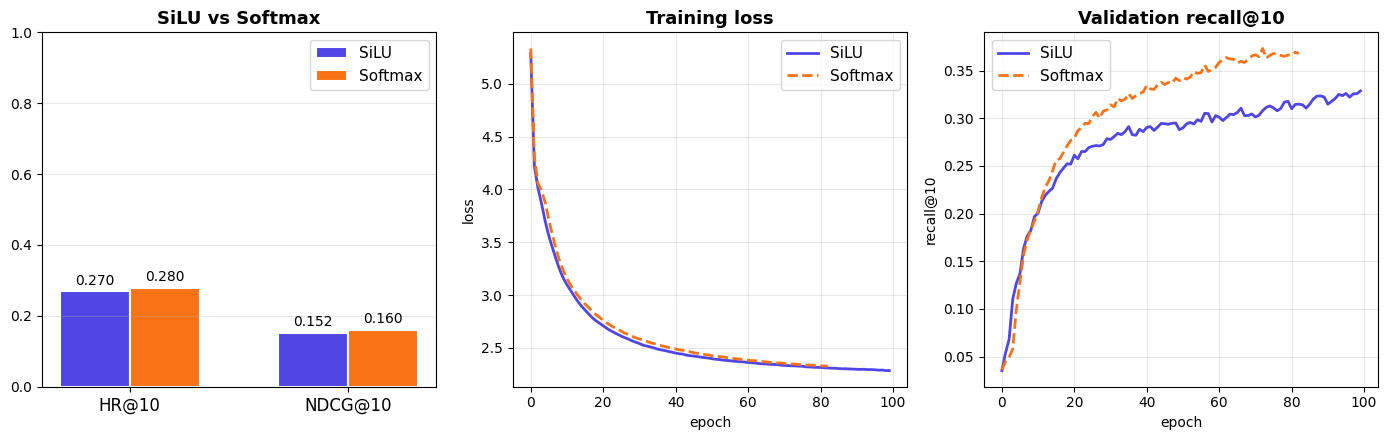

Model,HR@10,NDCG@10
HSTU (SiLU + actions),0.2697,0.1524
HSTU (Softmax + actions),0.2800,0.1602
Softmax vs SiLU,+3.8%,+5.1%


In [23]:
print("Training HSTU (SOFTMAX) for ablation — using with-actions dataset...")
model_softmax = make_model(use_softmax=True)
history_softmax = train(model_softmax, train_ds_act, val_ds_act)

hr_sm, ndcg_sm = evaluate(model_softmax, test_ds_act)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))

x = np.arange(2)
width = 0.32
bars1 = axes[0].bar(x - width/2, [hr_act, ndcg_act], width, label="SiLU",
                     color="#4f46e5", edgecolor="white", linewidth=1.5)
bars2 = axes[0].bar(x + width/2, [hr_sm, ndcg_sm], width, label="Softmax",
                     color="#f97316", edgecolor="white", linewidth=1.5)
axes[0].set_xticks(x)
axes[0].set_xticklabels(["HR@10", "NDCG@10"], fontsize=12)
axes[0].set_ylim(0, 1.0)
axes[0].legend(fontsize=11, loc="upper right")
axes[0].set_title("SiLU vs Softmax", fontsize=13, fontweight="bold")
axes[0].grid(axis="y", alpha=0.3)
for bar in bars1 + bars2:
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                 f"{bar.get_height():.3f}", ha="center", va="bottom", fontsize=10)

axes[1].plot(history_act["epoch"], history_act["train_loss"],
             color="#4f46e5", linewidth=2, label="SiLU")
axes[1].plot(history_softmax["epoch"], history_softmax["train_loss"],
             color="#f97316", linewidth=2, label="Softmax", linestyle="--")
axes[1].set_title("Training loss", fontsize=13, fontweight="bold")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("loss")
axes[1].legend(fontsize=11)
axes[1].grid(True, alpha=0.3)

axes[2].plot(history_act["epoch"], history_act["recall@10"],
             color="#4f46e5", linewidth=2, label="SiLU")
axes[2].plot(history_softmax["epoch"], history_softmax["recall@10"],
             color="#f97316", linewidth=2, label="Softmax", linestyle="--")
axes[2].set_title("Validation recall@10", fontsize=13, fontweight="bold")
axes[2].set_xlabel("epoch")
axes[2].set_ylabel("recall@10")
axes[2].legend(fontsize=11)
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

diff_hr = (hr_sm - hr_act) / hr_act * 100
diff_ndcg = (ndcg_sm - ndcg_act) / ndcg_act * 100
sign_hr = "+" if diff_hr >= 0 else ""
sign_ndcg = "+" if diff_ndcg >= 0 else ""
diff_color = "#22c55e" if abs(diff_hr) < 3 else ("#dc2626" if diff_hr < 0 else "#22c55e")

table_html = f"""
<div style="margin: 12px 0;">
<table style="border-collapse:collapse; font-size:14px; width:auto;">
  <tr style="background:#1e293b; color:white;">
    <th style="padding:10px 20px; text-align:left;">Model</th>
    <th style="padding:10px 20px; text-align:center;">HR@10</th>
    <th style="padding:10px 20px; text-align:center;">NDCG@10</th>
  </tr>
  <tr style="background:#f8fafc;">
    <td style="padding:10px 20px; font-weight:600; color:#4f46e5;">HSTU (SiLU + actions)</td>
    <td style="padding:10px 20px; text-align:center; font-family:monospace;">{hr_act:.4f}</td>
    <td style="padding:10px 20px; text-align:center; font-family:monospace;">{ndcg_act:.4f}</td>
  </tr>
  <tr style="background:#fff7ed;">
    <td style="padding:10px 20px; font-weight:600; color:#f97316;">HSTU (Softmax + actions)</td>
    <td style="padding:10px 20px; text-align:center; font-family:monospace;">{hr_sm:.4f}</td>
    <td style="padding:10px 20px; text-align:center; font-family:monospace;">{ndcg_sm:.4f}</td>
  </tr>
  <tr style="background:#f1f5f9;">
    <td style="padding:10px 20px; color:#64748b;">Softmax vs SiLU</td>
    <td style="padding:10px 20px; text-align:center; font-family:monospace; color:{diff_color};">{sign_hr}{diff_hr:.1f}%</td>
    <td style="padding:10px 20px; text-align:center; font-family:monospace; color:{diff_color};">{sign_ndcg}{diff_ndcg:.1f}%</td>
  </tr>
</table>
<p style="color:#94a3b8; font-size:12px; margin-top:6px;">
  At this scale ({NUM_ITEMS} items, T=200), the gap is within noise.
  SiLU's advantage emerges at production scale: longer sequences, larger catalogs, billions of training steps.
</p>
</div>
"""
display(HTML(table_html))

## 8. Inspect the learned time biases

The model learned, from gradient descent alone, that recent events should get more attention than old ones. Plot the bucket biases to see this directly.

/tmp/ipykernel_57/2580937549.py:13: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


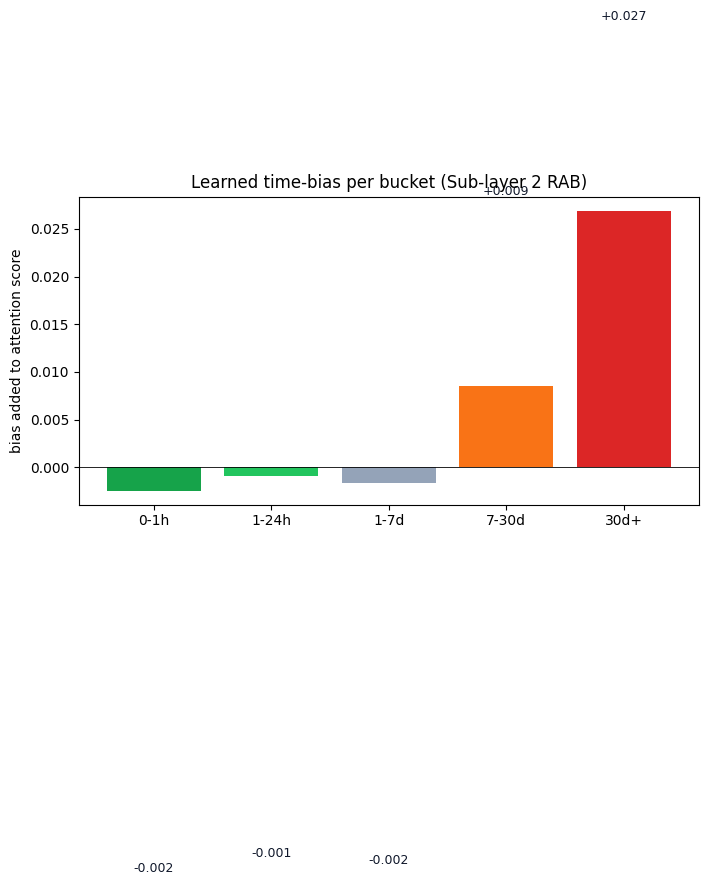


Learned time biases:
  0-1h      -0.0025
  1-24h     -0.0009
  1-7d      -0.0016
  7-30d     +0.0085
  30d+      +0.0269


In [24]:
time_biases = model.encoder.blocks[0].rab.time_bias.weight.detach().cpu().numpy().flatten()
bucket_labels = ["0-1h", "1-24h", "1-7d", "7-30d", "30d+"]

fig, ax = plt.subplots(figsize=(8, 4))
colors = ["#16a34a", "#22c55e", "#94a3b8", "#f97316", "#dc2626"]
ax.bar(bucket_labels, time_biases, color=colors)
ax.axhline(0, color="black", linewidth=0.6)
ax.set_title("Learned time-bias per bucket (Sub-layer 2 RAB)")
ax.set_ylabel("bias added to attention score")
for i, v in enumerate(time_biases):
    ax.text(i, v + (0.02 if v >= 0 else -0.04), f"{v:+.3f}",
            ha="center", fontsize=9, color="#0f172a")
plt.tight_layout()
plt.show()

print("\nLearned time biases:")
for label, b in zip(bucket_labels, time_biases):
    print(f"  {label:8s}  {b:+.4f}")

## 9. M-FALCON: cache-and-score inference

Scoring 10,000 candidates naively means running the full encoder 10,000 times \u2014 most of those FLOPs recompute the same user history. M-FALCON fixes this: run the encoder **once** over the user's history, cache K and V at every layer, then score each candidate with a single attention step against the cache.

In [25]:
@torch.no_grad()
def build_mfalcon_cache(model, hist_items, hist_actions, hist_times, attn_mask):
    """Run the encoder once over user history. Return cached K, V per layer + user_state."""
    model.eval()
    x = model.encoder.embed(hist_items, hist_actions)
    layer_cache = []

    for block in model.encoder.blocks:
        B, T, D = x.shape
        proj = F.silu(block.linear_in(x))
        K, Q, V, U = proj.chunk(4, dim=-1)

        layer_cache.append({"K": K.clone(), "V": V.clone()})

        scores = torch.matmul(Q, K.transpose(-2, -1))
        scores = scores + block.rab(hist_times)
        causal = torch.tril(torch.ones(T, T, device=x.device))
        pad_mask = attn_mask.unsqueeze(1).float()
        scores = scores * causal * pad_mask
        activated = F.silu(scores)
        attn_out = torch.matmul(activated, V) / max(T, 1)
        gated = block.norm(attn_out) * U
        output = block.linear_out(gated)
        x = output + x

    last_idx = attn_mask.sum(dim=1).clamp(min=1) - 1
    user_state = x[torch.arange(x.size(0), device=x.device), last_idx]
    return layer_cache, user_state


@torch.no_grad()
def mfalcon_score_candidates(model, layer_cache, hist_times, attn_mask,
                             candidate_ids, candidate_time):
    """Score a batch of candidates using cached K/V from history."""
    model.eval()
    C = candidate_ids.size(0)
    T_hist = hist_times.size(1)

    cand_actions = torch.ones_like(candidate_ids)
    x_c = model.encoder.embed(candidate_ids, cand_actions)
    x_c = x_c.unsqueeze(1)

    for layer_idx, block in enumerate(model.encoder.blocks):
        cached = layer_cache[layer_idx]
        K_hist = cached["K"].expand(C, -1, -1)
        V_hist = cached["V"].expand(C, -1, -1)

        proj_c = F.silu(block.linear_in(x_c))
        q_c, k_c, v_c, u_c = proj_c.chunk(4, dim=-1)

        K_full = torch.cat([K_hist, k_c], dim=1)
        V_full = torch.cat([V_hist, v_c], dim=1)

        scores = torch.matmul(q_c, K_full.transpose(-2, -1))

        idx_all = torch.arange(T_hist + 1, device=x_c.device)
        rel_pos = T_hist - idx_all + (block.rab.max_seq_len - 1)
        rel_pos = rel_pos.clamp(0, 2 * block.rab.max_seq_len - 2)
        pos_b = block.rab.pos_bias(rel_pos).squeeze(-1)

        hist_t = hist_times.squeeze(0)
        all_times = torch.cat([hist_t, candidate_time])
        time_deltas = (candidate_time - all_times).abs()
        bucket_idx = block.rab._bucket(time_deltas)
        time_b = block.rab.time_bias(bucket_idx).squeeze(-1)

        rab = (pos_b + time_b).unsqueeze(0).unsqueeze(0)
        scores = scores + rab

        pad = attn_mask.float().unsqueeze(0)
        cand_pad = torch.ones(1, 1, 1, device=x_c.device)
        full_pad = torch.cat([pad, cand_pad], dim=-1)
        scores = scores * full_pad

        activated = F.silu(scores)
        attn_out = torch.matmul(activated, V_full) / max(T_hist + 1, 1)
        gated = block.norm(attn_out) * u_c
        output = block.linear_out(gated)
        x_c = output + x_c

    return x_c.squeeze(1)


print("M-FALCON functions defined.")

M-FALCON functions defined.


### 9.1 Correctness check

The cache should produce the same user_state as a normal forward pass. If `allclose` passes, the cache is faithful.

In [26]:
sample = test_ds[0]
hist_items = torch.from_numpy(sample["hist_items"]).unsqueeze(0).to(device)
hist_actions = torch.from_numpy(sample["hist_actions"]).unsqueeze(0).to(device)
hist_times = torch.from_numpy(sample["hist_times"]).unsqueeze(0).to(device)
attn_mask = torch.ones_like(hist_items, dtype=torch.bool)

model.eval()
with torch.no_grad():
    _, user_state_naive = model(hist_items, hist_actions, hist_times, attn_mask)

cache, user_state_cached = build_mfalcon_cache(model, hist_items, hist_actions, hist_times, attn_mask)

match = torch.allclose(user_state_naive, user_state_cached, atol=1e-5)
max_diff = (user_state_naive - user_state_cached).abs().max().item()
print(f"user_state match: {match}  (max diff: {max_diff:.2e})")
print(f"Cached {len(cache)} layers, K shape per layer: {cache[0]['K'].shape}")

user_state match: True  (max diff: 0.00e+00)
Cached 2 layers, K shape per layer: torch.Size([1, 52, 64])


### 9.2 Speed benchmark: naive vs M-FALCON

In [27]:
NUM_CANDIDATES = 500

candidate_ids = torch.randint(1, NUM_ITEMS + 1, (NUM_CANDIDATES,), device=device)
candidate_time = hist_times[0, -1:] + 3600

model.eval()
if device == "cuda":
    torch.cuda.synchronize()
t0 = time.time()

with torch.no_grad():
    naive_scores = []
    for cid in candidate_ids:
        items_ext = torch.cat([hist_items, cid.view(1, 1)], dim=1)
        actions_ext = torch.cat([hist_actions, torch.ones(1, 1, dtype=torch.long, device=device)], dim=1)
        times_ext = torch.cat([hist_times, candidate_time.view(1, 1)], dim=1)
        mask_ext = torch.ones_like(items_ext, dtype=torch.bool)
        _, us = model(items_ext, actions_ext, times_ext, mask_ext)
        score = (us * model.encoder.embed.item_emb(cid.unsqueeze(0))).sum(-1)
        naive_scores.append(score.item())

if device == "cuda":
    torch.cuda.synchronize()
t_naive = time.time() - t0

if device == "cuda":
    torch.cuda.synchronize()
t0 = time.time()

cache, user_state_mf = build_mfalcon_cache(model, hist_items, hist_actions, hist_times, attn_mask)
cand_repr = mfalcon_score_candidates(model, cache, hist_times, attn_mask, candidate_ids, candidate_time)
mf_scores = (user_state_mf * cand_repr).sum(-1)

if device == "cuda":
    torch.cuda.synchronize()
t_mfalcon = time.time() - t0

speedup = t_naive / max(t_mfalcon, 1e-9)
print(f"History length:  {hist_items.size(1)}")
print(f"Candidates:      {NUM_CANDIDATES}")
print(f"Naive:           {t_naive:.3f}s  ({t_naive/NUM_CANDIDATES*1000:.1f} ms/candidate)")
print(f"M-FALCON:        {t_mfalcon:.3f}s  ({t_mfalcon/NUM_CANDIDATES*1000:.1f} ms/candidate)")
print(f"Speedup:         {speedup:.1f}x")

History length:  52
Candidates:      500
Naive:           1.195s  (2.4 ms/candidate)
M-FALCON:        0.006s  (0.0 ms/candidate)
Speedup:         210.4x


## 10. What's next

If you got this far and the model trained, you have a working HSTU with retrieval, ranking, FAISS indexing, and M-FALCON inference on MovieLens-1M. From here:

- **Scale up.** Bump `DIM` to 128 or 256, `NUM_LAYERS` to 4. Watch the loss curves and per-task metrics.
- **Add hard negatives.** Replace pure-uniform negative sampling with a mix of in-batch negatives + a small recent-negative buffer.
- **Try a bigger dataset.** Amazon Reviews 2023 is a natural next step. Same code, just point the data loader at a different source.
- **Compare with the Steam notebook.** The Steam version uses purchase/play/review events. Compare how rating-based action types (POSITIVE/NEUTRAL/NEGATIVE) affect the model's learned preferences.